In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
from sklearn.datasets import fetch_california_housing

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
from sklearn.linear_model import LinearRegression

In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [8]:
print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [10]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe())

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Summa

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [11]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records:
0


In [12]:
clean_df = df.copy()

print("Missing values before cleaning:",
      clean_df.isnull().sum().sum())

clean_df = clean_df.dropna()
clean_df = clean_df.drop_duplicates()

print("Missing values after cleaning:",
      clean_df.isnull().sum().sum())

print("Final dataset shape:", clean_df.shape)

Missing values before cleaning: 0
Missing values after cleaning: 0
Final dataset shape: (20640, 9)


In [13]:
X = clean_df[['MedInc']]

y = clean_df['MedHouseVal']

print("Input Feature (X):")
display(X.head())

print("Target Variable (y):")
display(y.head())

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature (X):


,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462


Target Variable (y):


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


Input Shape: (20640, 1)
Target Shape: (20640,)


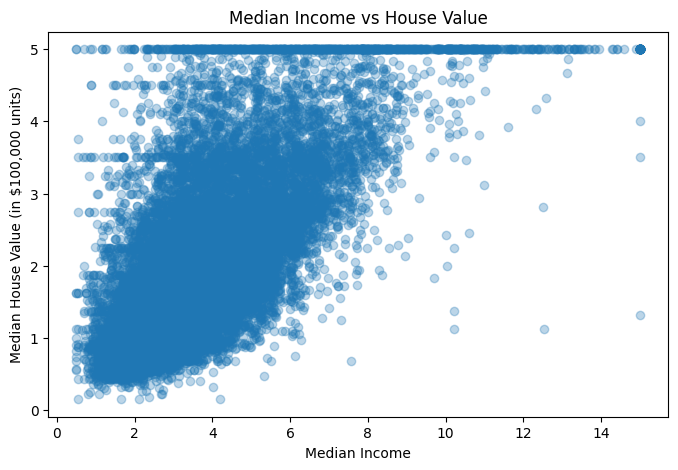

In [14]:
plt.figure(figsize=(8,5))

plt.scatter(
    X['MedInc'],
    y,
    alpha=0.3
)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value (in $100,000 units)")

plt.show()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 1)
Testing data: (4128, 1)


In [16]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [17]:
print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

Coefficient: 0.4193384939381271
Intercept: 0.4445972916907879


In [18]:
print("Linear Regression Equation:")

print(
    "House Price =",
    model.coef_[0],
    "* Median Income +",
    model.intercept_
)

Linear Regression Equation:
House Price = 0.4193384939381271 * Median Income + 0.4445972916907879


In [19]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [20]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison['Actual Price ($)'] = (
    comparison['Actual Price'] * 100000
)

comparison['Predicted Price ($)'] = (
    comparison['Predicted Price'] * 100000
)

display(comparison.head(10))

,Actual Price,Predicted Price,Actual Price ($),Predicted Price ($)
0,0.47700,1.149589,47700.0,114958.916770
1,0.45800,1.506069,45800.0,150606.882140
2,5.00001,1.903937,500001.0,190393.718444
3,2.18600,2.850594,218600.0,285059.383451
4,2.78000,2.006633,278000.0,200663.318161
5,1.58700,2.421652,158700.0,242165.248906
6,1.98200,2.576472,198200.0,257647.226102
7,1.57500,1.992292,157500.0,199229.180512
8,3.40000,2.458932,340000.0,245893.168117
9,4.46600,3.846774,446600.0,384677.436071


In [21]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)

print("Mean Squared Error (MSE):", mse)

print("Root Mean Squared Error (RMSE):", rmse)

print("R2 Score:", r2)

print("MAE in dollars:", mae * 100000)

print("RMSE in dollars:", rmse * 100000)

Mean Absolute Error (MAE): 0.629908653009376
Mean Squared Error (MSE): 0.7091157771765549
Root Mean Squared Error (RMSE): 0.8420901241414455
R2 Score: 0.45885918903846656
MAE in dollars: 62990.86530093761
RMSE in dollars: 84209.01241414454


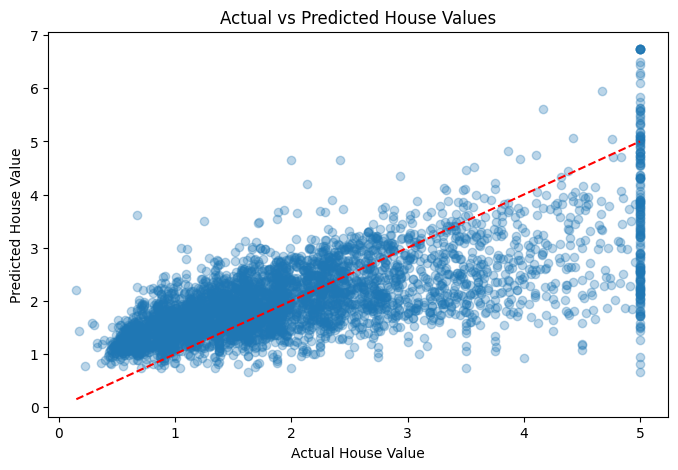

In [22]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

plt.show()

In [23]:
new_house = pd.DataFrame({
    'MedInc': [5.0]
})

predicted_value = model.predict(new_house)

price_in_dollars = predicted_value[0] * 100000

print("New House Median Income:", 5.0)

print("Predicted House Value:",
      predicted_value[0])

print("Predicted House Value in Dollars:",
      price_in_dollars)

New House Median Income: 5.0
Predicted House Value: 2.5412897613814236
Predicted House Value in Dollars: 254128.97613814235
